# 03- EXPLORATORY DATA ANALYSIS

#### El objetivo de este notebook es entender la distribución de las variables principales, analizar relaciones entre características y detectar patrones que puedan influir en las compras de los productos.

### 1. Importamos  las funciones y librerias necesarias.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.append("..")

from src.config import PROCESSED_DATA_PATH
from src.data_loader import load_csv

### 2. Cargamos el dataset limpio.

In [46]:
df = load_csv(PROCESSED_DATA_PATH)
df.head()

,title,rating,number_of_reviews,bought_in_last_month,current_discounted_price,price_on_variant,listed_price,is_best_seller,is_sponsored,is_couponed,...,sustainability_badges,collected_at,coupon_discount_value,coupon_discount_type,discount_amount,discount_percentage,title_length,title_word_count,has_free_delivery,has_fastest_delivery
0,BOYA BOYALINK 2 Wireless Lavalier Microphone f...,4.6,375.0,300.0,89.68,NaN,159.00,0,1,1,...,1,2025-08-21 11:14:29,15.0,percentage,69.32,43.60,199,30,0,0
1,"LISEN USB C to Lightning Cable, 240W 4 in 1 Ch...",4.3,2457.0,6000.0,9.99,NaN,15.99,0,1,0,...,0,2025-08-21 11:14:29,NaN,no_coupon,6.00,37.52,200,34,0,0
2,"DJI Mic 2 (2 TX + 1 RX + Charging Case), Wirel...",4.6,3044.0,2000.0,314.00,NaN,349.00,0,1,0,...,0,2025-08-21 11:14:29,NaN,no_coupon,35.00,10.03,193,29,0,0
3,"Apple AirPods Pro 2 Wireless Earbuds, Active N...",4.6,35882.0,10000.0,NaN,162.24,NaN,1,0,0,...,0,2025-08-21 11:14:29,NaN,no_coupon,NaN,NaN,194,24,0,0
4,Apple AirTag 4 Pack. Keep Track of and find Yo...,4.8,28988.0,10000.0,NaN,72.74,NaN,0,0,0,...,0,2025-08-21 11:14:29,NaN,no_coupon,NaN,NaN,133,24,0,0


#### `collected_at` se ha cargado como texto, lo covertimos.

In [47]:
df["collected_at"] = pd.to_datetime(df["collected_at"], errors="coerce")

### 3. Comprobración general.

In [48]:
df.shape

(42675, 21)

In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 42675 entries, 0 to 42674
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   title                     42675 non-null  str           
 1   rating                    41651 non-null  float64       
 2   number_of_reviews         41651 non-null  float64       
 3   bought_in_last_month      32164 non-null  float64       
 4   current_discounted_price  30926 non-null  float64       
 5   price_on_variant          20071 non-null  float64       
 6   listed_price              12311 non-null  float64       
 7   is_best_seller            42675 non-null  int64         
 8   is_sponsored              42675 non-null  int64         
 9   is_couponed               42675 non-null  int64         
 10  buy_box_availability      42675 non-null  int64         
 11  sustainability_badges     42675 non-null  int64         
 12  collected_at              426

In [50]:
df.isna().sum().sort_values(ascending=False)

coupon_discount_value       40727
discount_percentage         30364
discount_amount             30364
listed_price                30364
price_on_variant            22604
current_discounted_price    11749
bought_in_last_month        10511
number_of_reviews            1024
rating                       1024
title                           0
is_couponed                     0
is_best_seller                  0
is_sponsored                    0
collected_at                    0
sustainability_badges           0
buy_box_availability            0
coupon_discount_type            0
title_length                    0
title_word_count                0
has_free_delivery               0
has_fastest_delivery            0
dtype: int64

In [51]:
df.describe()

,rating,number_of_reviews,bought_in_last_month,current_discounted_price,price_on_variant,listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,sustainability_badges,collected_at,coupon_discount_value,discount_amount,discount_percentage,title_length,title_word_count,has_free_delivery,has_fastest_delivery
count,41651.000000,41651.000000,32164.000000,30926.000000,20071.000000,12311.000000,42675.000000,42675.000000,42675.000000,42675.000000,42675.000000,42675,1948.000000,12311.000000,12311.000000,42675.000000,42675.000000,42675.000000,42675.000000
mean,4.399431,3087.106000,1293.665278,212.607587,233.310187,214.461505,0.006444,0.164288,0.045647,0.656637,0.079859,2025-08-26 12:06:45.470463,22.999143,47.451059,21.598524,129.907042,20.127124,0.176731,0.132115
min,1.000000,1.000000,50.000000,2.490000,2.160000,4.950000,0.000000,0.000000,0.000000,0.000000,0.000000,2025-08-21 11:14:29,0.330000,0.470000,4.500000,12.000000,2.000000,0.000000,0.000000
25%,4.200000,82.000000,100.000000,25.990000,25.990000,27.330000,0.000000,0.000000,0.000000,0.000000,0.000000,2025-08-24 21:57:14,11.000000,5.000000,10.010000,73.000000,11.000000,0.000000,0.000000
50%,4.500000,343.000000,200.000000,77.000000,79.220000,59.990000,0.000000,0.000000,0.000000,1.000000,0.000000,2025-08-25 11:27:13,15.000000,14.000000,17.670000,146.000000,22.000000,0.000000,0.000000
75%,4.700000,1886.000000,400.000000,197.950000,216.660000,185.000000,0.000000,0.000000,0.000000,1.000000,0.000000,2025-08-29 11:22:04,25.000000,31.295000,30.010000,178.000000,27.000000,0.000000,0.000000
max,5.000000,865598.000000,100000.000000,4699.000000,5449.000000,5399.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2025-08-30 19:56:33,133.000000,2200.000000,85.420000,255.000000,45.000000,1.000000,1.000000
std,0.386997,13030.460133,6318.323574,389.888111,509.238027,443.524770,0.080017,0.370541,0.208722,0.474837,0.271079,NaN,22.370422,199.053889,14.517321,53.934316,8.771857,0.381445,0.338620


### 3. Analizamos la variable objetivo: `bought_in_last_month`.

In [52]:
df["bought_in_last_month"].describe()

count     32164.000000
mean       1293.665278
std        6318.323574
min          50.000000
25%         100.000000
50%         200.000000
75%         400.000000
max      100000.000000
Name: bought_in_last_month, dtype: float64

In [53]:
nul = df["bought_in_last_month"].isna().sum()
perc = df["bought_in_last_month"].isna().mean() * 100

print(f"Número de nulos: {nul}\n")
print(f"Porcentaje de nulos: {perc:.2f}%")


Número de nulos: 10511

Porcentaje de nulos: 24.63%


#### El 75.37% de los productos tienen información de compras recientes.
####

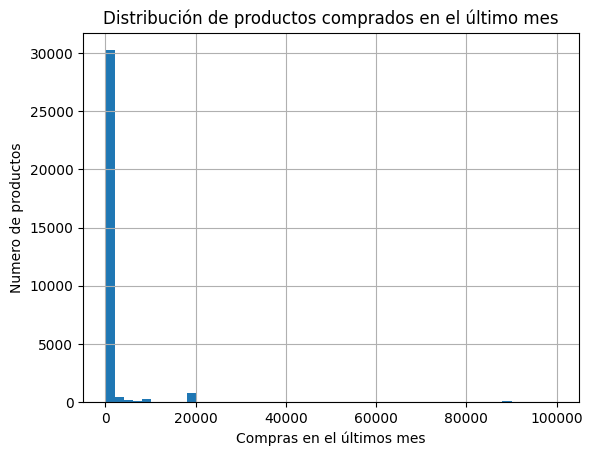

In [54]:
df["bought_in_last_month"].hist(bins=50)

plt.title("Distribución de productos comprados en el último mes")
plt.xlabel("Compras en el últimos mes")
plt.ylabel("Numero de productos")
plt.show()

#### La distribución muestra que la mayoría de productos tienen un volumen bajo de ventas, en cambio hay ciertos productos que tienen un volumen elevado, cercanos a las 90.000 unidades vendidas.
#### Por tanto, la variable analizada puede ser interesante, pero no tendría mucho sentido utilizarla con los valores actuales ya que está muy desbalanceada y sesgada hacia valores bajos. Para el proceso de modelado, habría que estudiar cambios como transformar la variable, agruparla en categorías, etc.

### 4. Realizamos transformaciones logarítmicas a la variable con el objetivo de analizar las nuevas distribuciones.

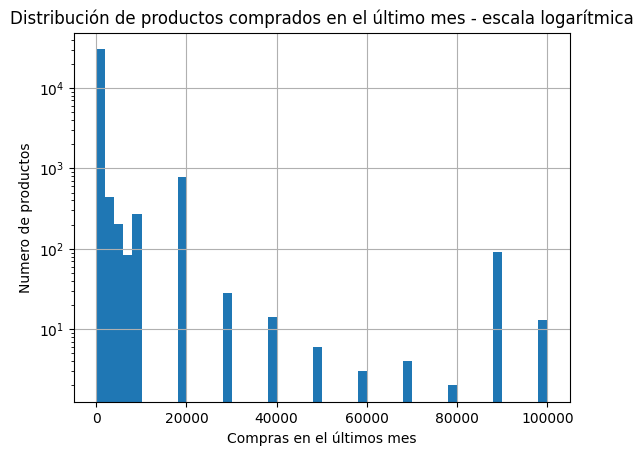

In [55]:
df["bought_in_last_month"].hist(bins=50)

plt.yscale("log")
plt.title("Distribución de productos comprados en el último mes - escala logarítmica")
plt.xlabel("Compras en el últimos mes")
plt.ylabel("Numero de productos")
plt.show()

#### El eje Y está en escala logarítmica y se aprecia perfectamente el número de ventas por productos, a diferencia de la distribución anterior dónde solo se apreciaba que casi todos los productos tenían pocas ventas.
####

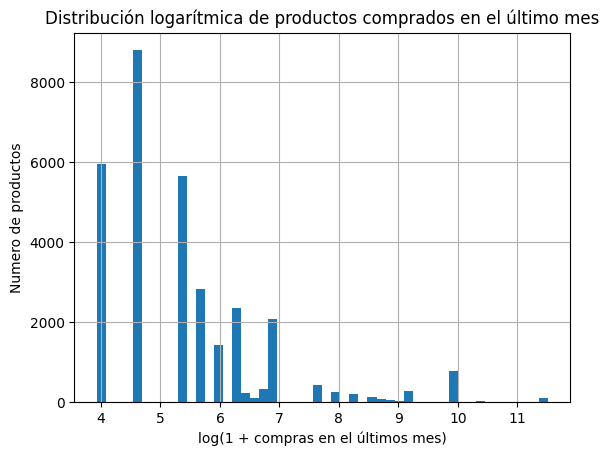

In [56]:
df["log_bought_in_last_month"] = np.log1p(df["bought_in_last_month"])

df["log_bought_in_last_month"].hist(bins=50)

plt.title("Distribución logarítmica de productos comprados en el último mes")
plt.xlabel("log(1 + compras en el últimos mes)")
plt.ylabel("Numero de productos")
plt.show()

#### En esta distribución se ha transformado la variable para comprobar si la transformación logarítmica puede ayudar en el modelo, reduciendo la diferencia entre valores.
####

In [57]:
df["bought_in_last_month"].value_counts().sort_index()

bought_in_last_month
50.0        5967
100.0       8801
200.0       5645
300.0       2842
400.0       1436
500.0       2351
600.0        229
700.0        102
800.0        280
900.0         63
1000.0      2084
2000.0       426
3000.0       249
4000.0       196
5000.0       120
6000.0        81
7000.0        49
8000.0        36
9000.0        44
10000.0      229
20000.0      772
30000.0       28
40000.0       14
50000.0        6
60000.0        3
70000.0        4
80000.0        2
90000.0       92
100000.0      13
Name: count, dtype: int64

### 5. Creamos categorías por el nivel de ventas.

In [58]:
def classify_sales(value):
    if pd.isna(value):
        return np.nan
    elif value <= 100:
        return "low"
    elif value <= 1000:
        return "medium"
    elif value <= 10000:
        return "high"
    else:
        return "very_high"
    

df["sales_category"] = df["bought_in_last_month"].apply(classify_sales)

df["sales_category"].value_counts()

sales_category
medium       15032
low          14768
high          1430
very_high      934
Name: count, dtype: int64

### 6. Representamos la variable por etiquetas creada.

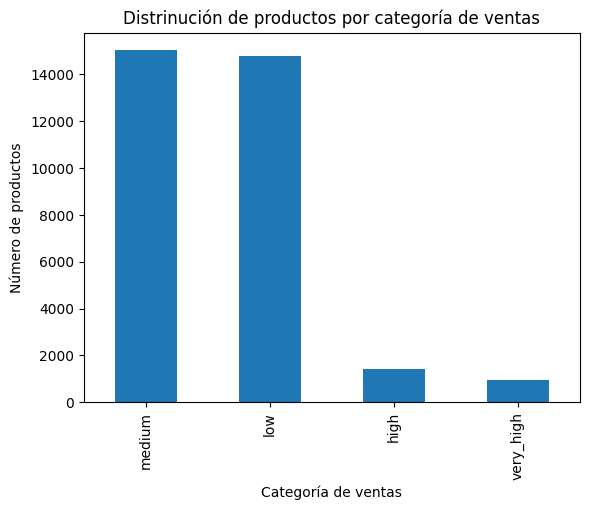

In [59]:
df["sales_category"].value_counts().plot(kind="bar")

plt.title("Distrinución de productos por categoría de ventas")
plt.xlabel("Categoría de ventas")
plt.ylabel("Número de productos")
plt.show()

#### La gráfica muestra como se distribuyen las ventas según categoría.
#### Para el proceso de modelado, se tendrán encuenta tanto regresión sobre la variable logirítmica transformada y clasificación por categoría de ventas.

In [60]:
df["sales_category"].value_counts()

sales_category
medium       15032
low          14768
high          1430
very_high      934
Name: count, dtype: int64

#### La variable `sales_category` está desbalanceada. Las categoría `low` y `medium` tienen la mayor parte de los productos.
#### Esto confirma que la mayoría de productos se concentran en niveles bajos de ventas en el último mes.
#### A la hora del modelado, deberá tenerse en cuenta si se planteaa como clasificación ya que podría favorecer a las clases mayoritarias.
####

### 7. Análisis de las variables: `rating` y `number_of_reviews`.

##### ¿Los productos con más ventas tienen mejor valoración?
##### ¿Los productos con más ventas tienen más reseñas?
##### ¿El número de reseñas parece más importante que la valoración?
##### ¿Hay productos muy vendidos con rating bajo?
#####

In [61]:
df["rating"].describe()

count    41651.000000
mean         4.399431
std          0.386997
min          1.000000
25%          4.200000
50%          4.500000
75%          4.700000
max          5.000000
Name: rating, dtype: float64

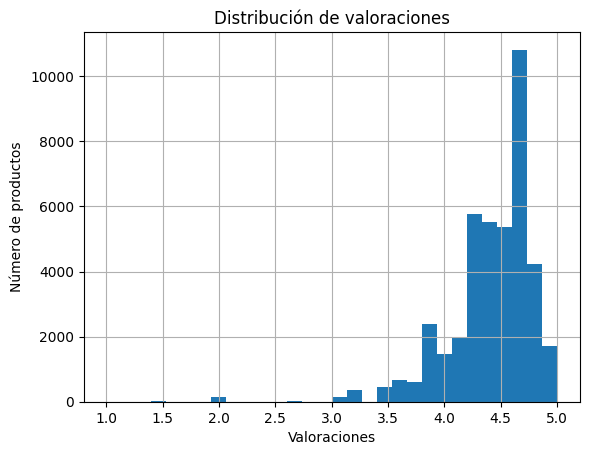

In [62]:
df["rating"].hist(bins=30)

plt.title("Distribución de valoraciones")
plt.xlabel("Valoraciones")
plt.ylabel("Número de productos")
plt.show()

In [63]:
df["number_of_reviews"].describe()

count     41651.000000
mean       3087.106000
std       13030.460133
min           1.000000
25%          82.000000
50%         343.000000
75%        1886.000000
max      865598.000000
Name: number_of_reviews, dtype: float64

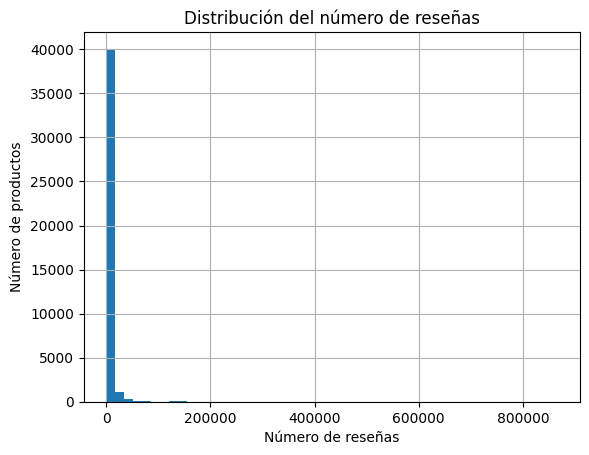

In [64]:
df["number_of_reviews"].hist(bins=50)

plt.title("Distribución del número de reseñas")
plt.xlabel("Número de reseñas")
plt.ylabel("Número de productos")
plt.show()

#### De la misma manera que en la distribución de `bought_in_last_month`, la gráfica no nos permite ver la información con claridad. Por eso, se realizan las transformaciones logarítmicas necesarias.
####

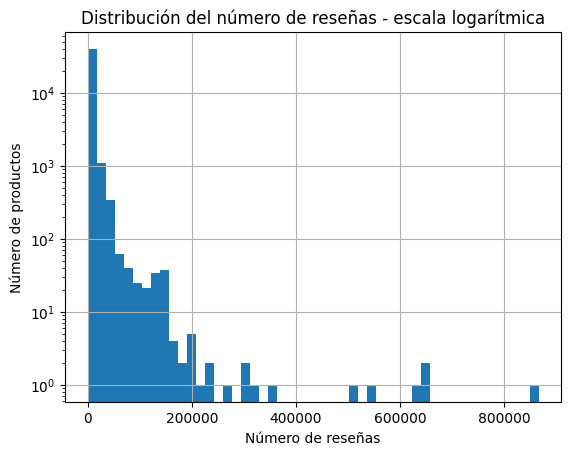

In [65]:
df["number_of_reviews"].hist(bins=50)

plt.yscale("log")
plt.title("Distribución del número de reseñas - escala logarítmica")
plt.xlabel("Número de reseñas")
plt.ylabel("Número de productos")
plt.show()

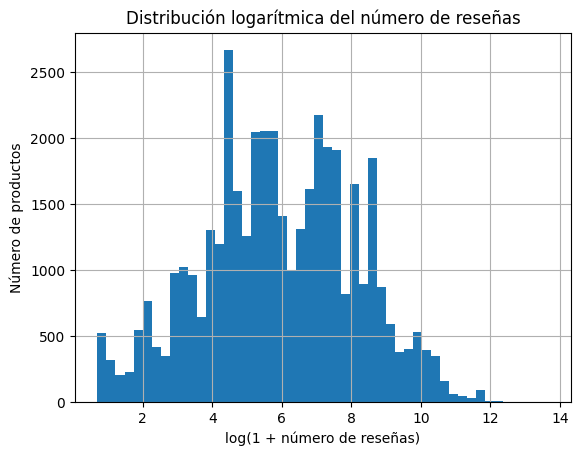

In [66]:
df["log_number_of_reviews"] = np.log1p(df["number_of_reviews"])

df["log_number_of_reviews"].hist(bins=50)

plt.title("Distribución logarítmica del número de reseñas")
plt.xlabel("log(1 + número de reseñas)")
plt.ylabel("Número de productos")
plt.show()

#### 8. Comparamos cada variable con ventas.

In [67]:
# Valoración media que tienen los productos de cada categoría de venta.
# La media representa bein el comportamiento general del grupo porque no hay valores extremos y está en un rango de 1 a 5.
df.groupby("sales_category")["rating"].mean().sort_values()

sales_category
low          4.335738
medium       4.475745
high         4.517552
very_high    4.790792
Name: rating, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

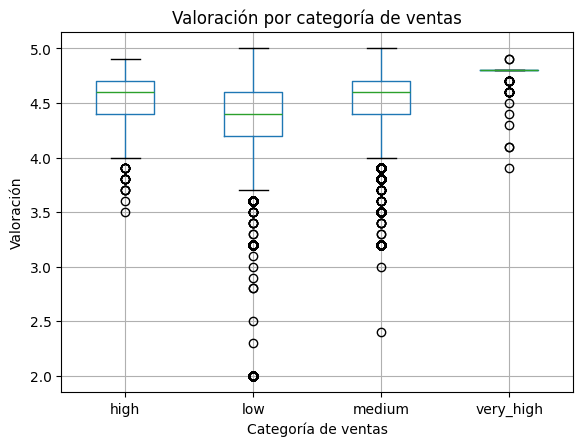

In [68]:
df.boxplot(column="rating", by="sales_category")

plt.title("Valoración por categoría de ventas")
plt.suptitle("")
plt.xlabel("Categoría de ventas")
plt.ylabel("Valoración")
plt.show

In [69]:
# Número típico de reseñas en cada categoría de ventas.
# En este caso, la media no representaría bien el comportamiento general porque hay valores extremos muy altos que distorsionarían la realidad.
df.groupby("sales_category")["number_of_reviews"].median().sort_values()

sales_category
low           260.0
medium       1261.0
very_high    5242.0
high         8991.0
Name: number_of_reviews, dtype: float64

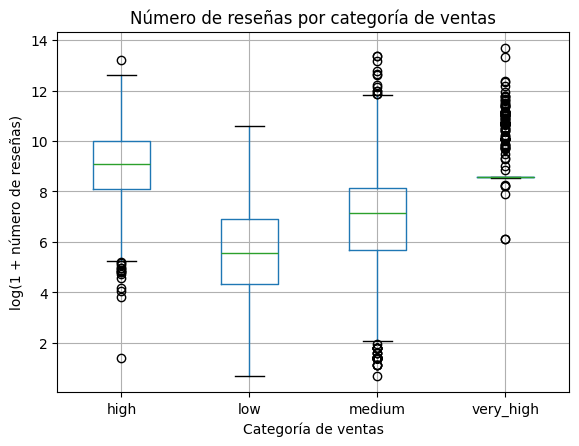

In [70]:
df.boxplot(column="log_number_of_reviews", by="sales_category")

plt.title("Número de reseñas por categoría de ventas")
plt.suptitle("")
plt.xlabel("Categoría de ventas")
plt.ylabel("log(1 + número de reseñas)")
plt.show()

#### Tras el análisis de ambas variables podemos sacar las siguiente conclusiones:
#### 1. A medida que aumenta la categoría de ventas, aumenta la valoración media.
#### Tiene sentido que los productos más vendidos tengan mejores valoraciones.
#### 2. De la misma manera, a medida que aumenta la categoría, aumenta el número de valoraciones. Sin embargo, la categoría `high` presenta una mediana superior a `very_high`. 
#### Este suceso indica que no es una relación completamente lineal y puede ser debido a que `number_of_reviews` representa reseñas acumuladas históricamente y que `bought_in_last_month` representa las ventas en el último mes.
####
#### En conclusión, ambas variables están relacionadas con el volumen de ventas y pueden ser útiles para el modelo.

In [71]:
df["sales_category"].value_counts()

sales_category
medium       15032
low          14768
high          1430
very_high      934
Name: count, dtype: int64

### 9. Analizamos precios y descuentos.

##### ¿Los productos más vendidos son más baratos?
##### ¿El descuento influye en las ventas?
##### ¿Los productos con ventas altas tienen mayor porcentaje de descuento?
#####

In [72]:
df[["current_discounted_price", "listed_price", "discount_amount", "discount_percentage"]].describe()

,current_discounted_price,listed_price,discount_amount,discount_percentage
count,30926.000000,12311.000000,12311.000000,12311.000000
mean,212.607587,214.461505,47.451059,21.598524
std,389.888111,443.524770,199.053889,14.517321
min,2.490000,4.950000,0.470000,4.500000
25%,25.990000,27.330000,5.000000,10.010000
50%,77.000000,59.990000,14.000000,17.670000
75%,197.950000,185.000000,31.295000,30.010000
max,4699.000000,5399.000000,2200.000000,85.420000


In [73]:
df.groupby("sales_category")["current_discounted_price"].median().sort_values()

sales_category
high          24.98
very_high     25.47
medium        29.69
low          169.95
Name: current_discounted_price, dtype: float64

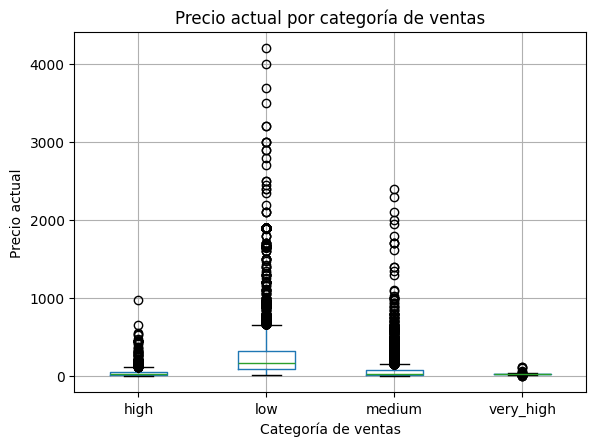

In [74]:
df.boxplot(column="current_discounted_price", by="sales_category")

plt.title("Precio actual por categoría de ventas")
plt.suptitle("")
plt.xlabel("Categoría de ventas")
plt.ylabel("Precio actual")
plt.show()

#### Aplicamos transformación logarítmica para que se vean mejor las características.

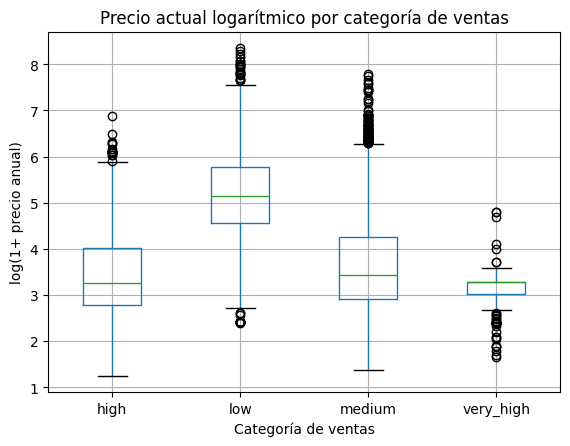

In [75]:
df["log_current_price"] = np.log1p(df["current_discounted_price"])

df.boxplot(column="log_current_price", by="sales_category")

plt.title("Precio actual logarítmico por categoría de ventas")
plt.suptitle("")
plt.xlabel("Categoría de ventas")
plt.ylabel("log(1+ precio anual)")
plt.show()

In [76]:
df.groupby("sales_category")["discount_percentage"].median().sort_values()

sales_category
very_high    15.350
low          18.750
medium       19.250
high         24.845
Name: discount_percentage, dtype: float64

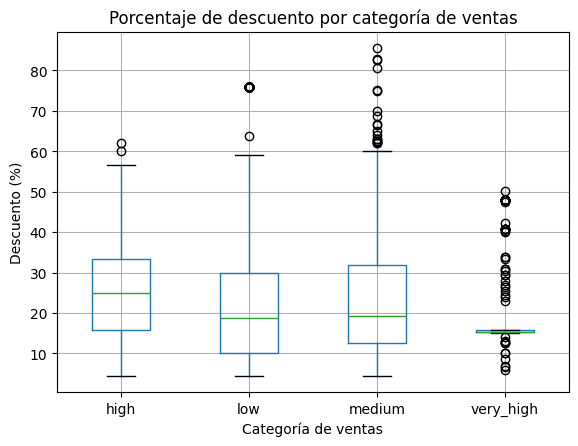

In [77]:
df.boxplot(column="discount_percentage", by="sales_category")

plt.title("Porcentaje de descuento por categoría de ventas")
plt.suptitle("")
plt.xlabel("Categoría de ventas")
plt.ylabel("Descuento (%)")
plt.show()

#### Tras el análisis de las variables podemos sacar las siguiente conclusiones:
#### 1. Los precios muestran una clara diferencia entre las categorías de ventas. Los productos con menos ventas tienen una mediana superior.
#### En resumen, los productos más caros se venden menos.
#### 2. En los descuentos, la relación no es tan directa. 
#### Esta variable, puede ser relavante pero no es suficiente por si sola para explicar las ventas.
####
#### En conclusión, las variables analizadas pueden ser útiles para el modelado pero hay que ir con cuidado por los nulos y valores extremos.
####

### 10. Analizamos las variables comerciales: `sponsored`, `coupon`, `best seller` y `delivery`.


In [78]:
commercial_columns =[
    "is_sponsored",
    "is_couponed",
    "is_best_seller",
    "has_free_delivery",
    "has_fastest_delivery"
]

df.groupby("sales_category")[commercial_columns].mean()

,is_sponsored,is_couponed,is_best_seller,has_free_delivery,has_fastest_delivery
sales_category,,,,,
high,0.236364,0.030070,0.109091,0.097902,0.096503
low,0.043811,0.014626,0.001625,0.196574,0.140574
medium,0.116418,0.057278,0.004258,0.207358,0.176690
very_high,0.929336,0.001071,0.026767,0.143469,0.144540


#### Tras el análisis de las variables podemos sacar las siguiente conclusiones:
#### 1. La variable `is_sponsored` es la variable con mayor relación con el volumen de compras. La proporción de productos patrocinados aumenta a medida que el volumen de ventas aumenta.
#### 2. La variable `best_seller` también está relacionada, especialmente en la categoría `high` aunque no sigue un tendencia lineal.
#### 3. El resto de variables no tienen una relación clara con las ventas.
####

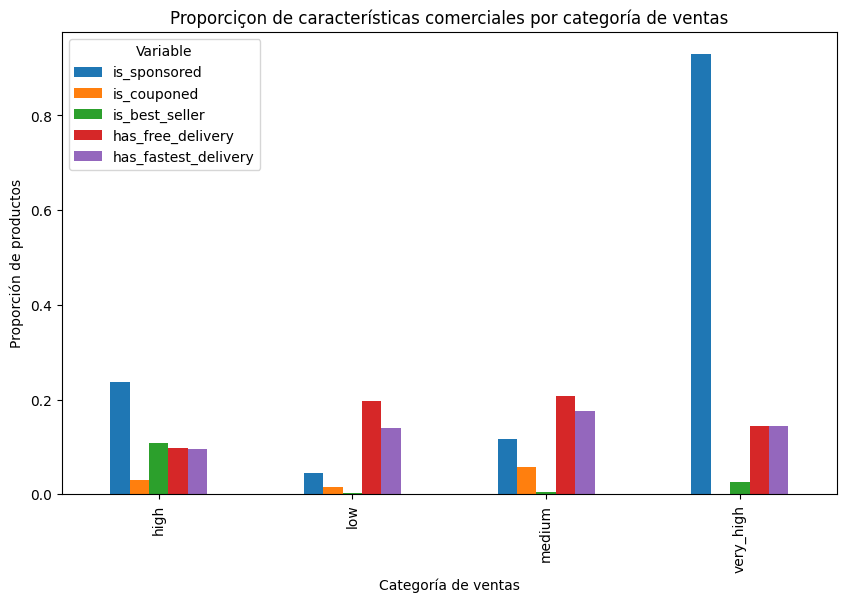

In [79]:
commercial_summary = df.groupby("sales_category")[commercial_columns].mean()

commercial_summary.plot(kind="bar",figsize=(10,6))

plt.title("Proporciçon de características comerciales por categoría de ventas")
plt.xlabel("Categoría de ventas")
plt.ylabel("Proporción de productos")
plt.legend(title="Variable")
plt.show()

### 11. Correlaciones entre variables numéricas

In [80]:
numeric_columns = [
    "rating",
    "number_of_reviews",
    "bought_in_last_month",
    "current_discounted_price",
    "price_on_variant",
    "listed_price",
    "discount_amount",
    "discount_percentage",
    "coupon_discount_value",
    "is_best_seller",
    "is_sponsored",
    "is_couponed",
    "buy_box_availability",
    "sustainability_badges",
    "has_free_delivery",
    "has_fastest_delivery",
    "title_length",
    "title_word_count"
]

corr_matrix = df[numeric_columns].corr()

corr_matrix

,rating,number_of_reviews,bought_in_last_month,current_discounted_price,price_on_variant,listed_price,discount_amount,discount_percentage,coupon_discount_value,is_best_seller,is_sponsored,is_couponed,buy_box_availability,sustainability_badges,has_free_delivery,has_fastest_delivery,title_length,title_word_count
rating,1.000000,0.099750,0.151883,-0.210641,-0.104052,0.029211,0.046955,-0.039807,-0.170161,0.027851,0.023373,-0.044077,0.143505,0.001548,-0.026039,0.010425,-0.067957,-0.022355
number_of_reviews,0.099750,1.000000,0.295952,-0.093670,-0.068452,-0.094226,-0.049455,-0.011890,-0.099360,0.191605,0.029195,-0.021615,0.021530,0.112177,-0.018965,0.001422,0.006133,-0.003641
bought_in_last_month,0.151883,0.295952,1.000000,-0.097978,-0.059051,-0.078639,-0.040927,-0.046063,-0.288129,0.115336,0.359071,-0.016152,0.080369,-0.010029,-0.040502,-0.024070,0.033656,0.018971
current_discounted_price,-0.210641,-0.093670,-0.097978,1.000000,0.877279,0.903607,0.298334,-0.192806,0.821028,-0.030767,-0.099162,-0.016123,0.004023,-0.062912,0.072710,0.053241,0.040513,0.083199
price_on_variant,-0.104052,-0.068452,-0.059051,0.877279,1.000000,0.967658,0.636015,-0.053551,0.671906,-0.022778,-0.021427,-0.052327,-0.196402,-0.034438,-0.077459,-0.080767,0.186288,0.150064
listed_price,0.029211,-0.094226,-0.078639,0.903607,0.967658,1.000000,0.678432,0.017547,0.336072,-0.031223,-0.125505,-0.036371,-0.183151,-0.065481,0.099791,0.117933,0.119329,0.182971
discount_amount,0.046955,-0.049455,-0.040927,0.298334,0.636015,0.678432,1.000000,0.369770,0.281555,-0.015436,-0.069310,-0.027221,-0.238280,-0.041334,0.166871,0.179841,0.123496,0.162570
discount_percentage,-0.039807,-0.011890,-0.046063,-0.192806,-0.053551,0.017547,0.369770,1.000000,-0.554985,0.032452,-0.002739,0.015573,-0.140506,0.041513,-0.030231,-0.008376,0.092042,0.126512
coupon_discount_value,-0.170161,-0.099360,-0.288129,0.821028,0.671906,0.336072,0.281555,-0.554985,1.000000,-0.030685,-0.279035,NaN,0.078837,-0.023960,0.550604,0.109477,0.178081,0.324657
is_best_seller,0.027851,0.191605,0.115336,-0.030767,-0.022778,-0.031223,-0.015436,0.032452,-0.030685,1.000000,0.007762,-0.007791,0.010747,0.037854,0.005681,0.015281,0.007458,0.009349


####
#### ¿Qué variables están más asociadas con las compras recientes?
####

In [81]:
corr_matrix["bought_in_last_month"].sort_values(ascending=False)

bought_in_last_month        1.000000
is_sponsored                0.359071
number_of_reviews           0.295952
rating                      0.151883
is_best_seller              0.115336
buy_box_availability        0.080369
title_length                0.033656
title_word_count            0.018971
sustainability_badges      -0.010029
is_couponed                -0.016152
has_fastest_delivery       -0.024070
has_free_delivery          -0.040502
discount_amount            -0.040927
discount_percentage        -0.046063
price_on_variant           -0.059051
listed_price               -0.078639
current_discounted_price   -0.097978
coupon_discount_value      -0.288129
Name: bought_in_last_month, dtype: float64

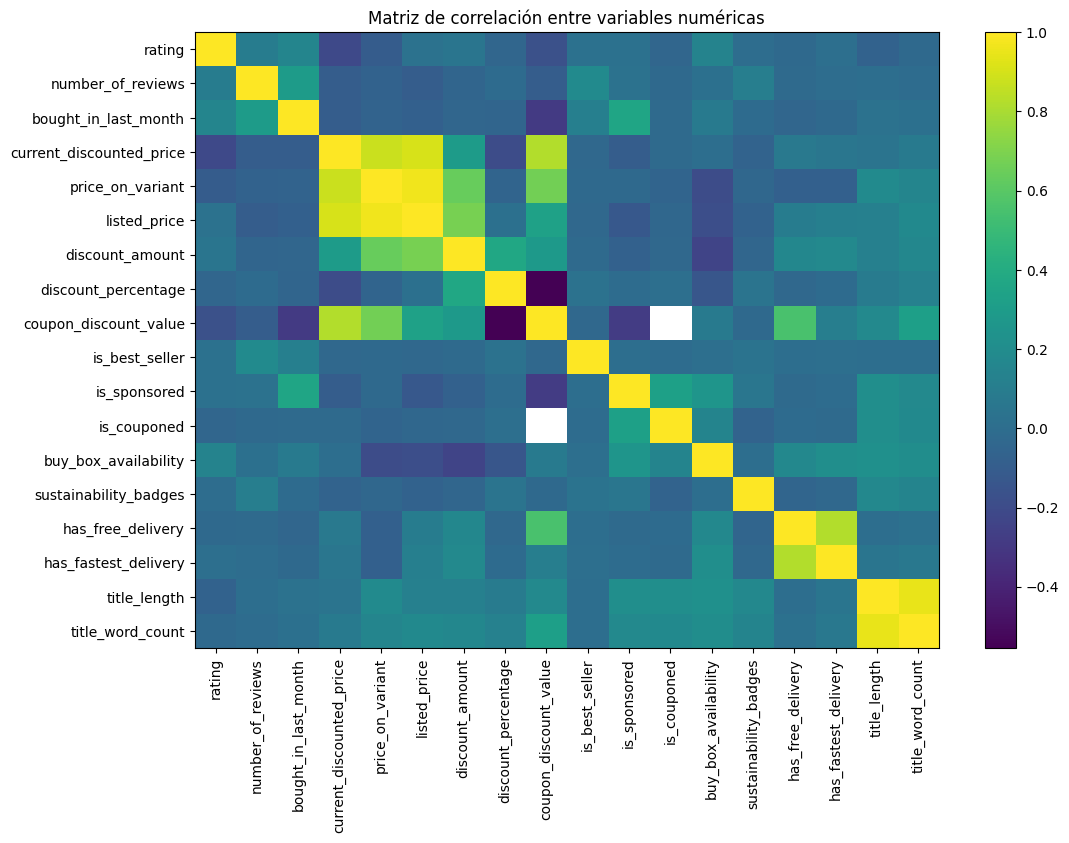

In [ ]:
plt.figure(figsize=(12,8))

plt.imshow(corr_matrix, aspect="auto")
plt.colorbar()

plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

plt.title("Matriz de correlación entre variables numéricas")

plt.show()

#### La variable más relacionadas con las compras en el último mes `is_sponsored` y por detrás le siguen `number_of_views`, `rating` y `is_best_seller`. Esto verifica nuestro análisis anterior.
#### La visibilidad, la reputación acumulada y la valoración están relacionadas con un mayor número de ventas.
#### Por otra parte, podemos observar como hay variables que presentan correlación negativa. Esto indica que los productos más caros se venden menos, algo esperable.
####

In [83]:
# Miramos la versión logarítmica ya que hemos visto que 'bought_in_last_month' está sesgada.
df["log_bought_in_last_month"] = np.log1p(df["bought_in_last_month"])

numeric_columns_with_log = numeric_columns + ["log_bought_in_last_month"]

corr_matrix_log = df[numeric_columns_with_log].corr()

corr_matrix_log["log_bought_in_last_month"].sort_values(ascending=False)

log_bought_in_last_month    1.000000
bought_in_last_month        0.597716
is_sponsored                0.463059
number_of_reviews           0.285017
rating                      0.276529
buy_box_availability        0.183621
is_best_seller              0.176788
is_couponed                 0.095760
title_length                0.062406
title_word_count            0.059861
sustainability_badges       0.056868
discount_percentage        -0.009471
has_fastest_delivery       -0.010124
has_free_delivery          -0.058667
discount_amount            -0.182431
listed_price               -0.306987
price_on_variant           -0.327386
current_discounted_price   -0.382080
coupon_discount_value      -0.711625
Name: log_bought_in_last_month, dtype: float64


#### Al analizar la correlación con la transformación logarítmica, se puede observar un comportamiento muy similar, siendo `is_sponsored` la variable más relacionada, seguidas por `number_of_views`, `rating` y `is_best_seller`. 
#### 

## Conclusión final del EDA

### El análisis exploratorio muestra que la variable `bought_in_last_month` tiene una distribución muy asimétrica, con muchos productos concentrados en niveles bajos de compras y una pequeña cantidad de productos con valores muy altos. 

### A partir del análisis por categorías de ventas, se observa que los productos con mayores ventas suelen tener mejor rating, más reseñas, precios más bajos y una mayor proporción de productos patrocinados.

### Las variables más relacionadas con las compras recientes son `is_sponsored`, `number_of_reviews`, `rating` y `is_best_seller`. En cambio, las variables relacionadas con el precio que muestran una relación negativa indica que los productos tienen menor volumen de ventas.

### De cara al modelado, se plantean dos posibles enfoques. El primero sería un modelo de regresión utilizando una transformación logarítmica de `bought_in_last_month`. El segundo sería un modelo de clasificación utilizando la variable `sales_category`.

### Debido a que las ventas parece que son aproximaciones agrupadas y no valores exactos, el enfoque de clasificación por categorías de ventas parece el más adecuado.
